# Financial Fragility Framework — full historical CORE

**Final descriptive reference:** all available financial club-years in the project's approved 2016–2025 CORE (339 rows across 35 clubs in the published snapshot). This notebook replaces the partial-sample framework that preceded the historical collection expansion.

The three original indicators, percentile directions and equal weighting are retained, but **all percentile scores are recalculated** using the complete historical reference. This is a retrospective comparison, **not a credit rating, a probability-of-default model, or a feature used by the predictive notebooks**. See [`docs/fragility_framework.md`](../docs/fragility_framework.md).

## 1. Rebuild and audit from the full CORE

Read the canonical CORE, run independent structural checks, and regenerate both active framework CSVs with the shared `src/build_financial_fragility.py` implementation.

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path('..').resolve()
sys.path.insert(0, str(PROJECT_ROOT / 'src'))
from build_financial_fragility import build_fragility, main, CORE_VARIABLES, INDICATORS, RISK_COMPONENTS

pd.set_option('display.float_format', lambda x: f'{x:.3f}')
core = pd.read_csv(PROJECT_ROOT / 'data/processed/core_financials.csv')
assert core['club'].notna().all()
assert not core.duplicated(['club', 'fiscal_year']).any()
assert core[CORE_VARIABLES].notna().all().all()

scores, reference = build_fragility(core)
main()  # regenerate the active CSVs from the same validated CORE
print(f'{scores.club.nunique()} clubs | {len(scores)} documented club-years | '
      f'{scores.fiscal_year.min()}–{scores.fiscal_year.max()}')
print('Unavailable club-years in the rectangular panel:',
      scores.club.nunique() * scores.fiscal_year.nunique() - len(scores))

Full CORE source: C:\Users\mathe\OneDrive\Desktop\Projetos\football-credit-risk\data\processed\core_financials.csv
Clubs: 35
Club-years: 339
Fiscal years: 2016 - 2025
Gaps against rectangular panel: 11
Scores: C:\Users\mathe\OneDrive\Desktop\Projetos\football-credit-risk\data\processed\financial_fragility_scores.csv
Reference: C:\Users\mathe\OneDrive\Desktop\Projetos\football-credit-risk\data\processed\fragility_reference.csv
QA: passed
35 clubs | 339 documented club-years | 2016–2025
Unavailable club-years in the rectangular panel: 11


In [2]:
coverage = (scores.groupby('fiscal_year')['club']
            .agg(clubs='nunique', club_years='size'))
coverage

,clubs,club_years
fiscal_year,,
2016,33,33
2017,33,33
2018,33,33
2019,33,33
2020,35,35
2021,35,35
2022,35,35
2023,35,35
2024,34,34


## 2. Financial indicators and pooled reference

- Current liquidity: current assets / current liabilities (lower → greater risk).
- Liability ratio: total liabilities / total assets (higher → greater risk).
- Return on assets: net result / total assets (lower → greater risk).

Each component uses percentile ranks across **all documented club-years together**, with equally weighted components. The same percentile reference is used when comparing 2016 with 2025.

In [3]:
# Independently reconstruct the three ratio definitions and risk directions.
independent = core[['club', 'fiscal_year', *CORE_VARIABLES]].copy()
independent['current_liquidity'] = (independent.current_assets /
                                    independent.current_liabilities)
independent['liability_ratio'] = (independent.total_liabilities /
                                  independent.total_assets)
independent['return_on_assets'] = (independent.net_result /
                                   independent.total_assets)
independent['liquidity_risk'] = (1 - independent.current_liquidity.rank(pct=True)) * 100
independent['solvency_risk'] = independent.liability_ratio.rank(pct=True) * 100
independent['profitability_risk'] = (1 - independent.return_on_assets.rank(pct=True)) * 100
independent['financial_fragility_score'] = independent[RISK_COMPONENTS].mean(axis=1)
independent = independent.sort_values(['club', 'fiscal_year']).reset_index(drop=True)

for col in [*INDICATORS, *RISK_COMPONENTS, 'financial_fragility_score']:
    np.testing.assert_allclose(independent[col], scores[col], rtol=1e-12, atol=1e-12)

assert len(scores) == len(core) == len(reference)
assert scores[INDICATORS + RISK_COMPONENTS + ['financial_fragility_score']].notna().all().all()
assert scores[RISK_COMPONENTS + ['financial_fragility_score']].apply(
    lambda col: col.between(0, 100).all()).all()
scores[['current_liquidity', 'liability_ratio', 'return_on_assets',
        'financial_fragility_score']].describe()

,current_liquidity,liability_ratio,return_on_assets,financial_fragility_score
count,339.000,339.000,339.000,339.000
mean,0.947,1.427,-0.077,49.951
std,2.981,1.496,0.467,22.383
min,0.000,0.034,-5.043,2.065
25%,0.163,0.718,-0.123,36.087
50%,0.363,1.031,-0.014,49.951
75%,0.688,1.443,0.062,65.683
max,41.392,9.736,1.060,99.017


## 3. Historical losses and documentary gaps

The historical prior-loss rate excludes the current fiscal year. It may include older **observed** years even when a documentary gap exists. By contrast, the SQL view's change in fragility score is annual only if the immediately preceding fiscal year exists.

In [4]:
expected_loss_history = (scores.groupby('club')['net_result']
    .transform(lambda s: s.lt(0).shift().expanding().mean()))
np.testing.assert_allclose(scores.previous_loss_rate,
                            expected_loss_history, equal_nan=True)
assert scores.groupby('club').head(1).previous_loss_rate.isna().all()

all_clubs = sorted(scores.club.unique())
all_years = sorted(scores.fiscal_year.unique())
complete_keys = pd.MultiIndex.from_product([all_clubs, all_years],
                                           names=['club', 'fiscal_year'])
observed_keys = pd.MultiIndex.from_frame(scores[['club', 'fiscal_year']])
missing_keys = complete_keys.difference(observed_keys)
print('Documentary gaps:', len(missing_keys))
print(missing_keys.to_frame(index=False).to_string(index=False))

Documentary gaps: 11
       club  fiscal_year
        CSA         2025
     Cuiabá         2016
Figueirense         2024
Figueirense         2025
   Mirassol         2019
       Remo         2016
       Remo         2017
       Remo         2018
    Vitória         2017
    Vitória         2018
    Vitória         2019


## 4. Descriptive interpretation and sensitivity checks

Check association with the independent negative-equity indicator and previously observed accounting losses. These are **descriptive associations**, not predictive validation. Compare equal weights with one dimension receiving 50% weight; assess normalization sensitivity separately.

In [5]:
equity_check = scores.groupby('negative_equity')['financial_fragility_score'].agg(
    observations='size', median='median', mean='mean')
prior_loss_spearman = scores[['financial_fragility_score', 'previous_loss_rate']].corr(
    method='spearman')
print('Negative-equity descriptive check:')
print(equity_check)
print('Spearman score vs prior observed loss rate:')
print(prior_loss_spearman)

Negative-equity descriptive check:
                 observations  median   mean
negative_equity                             
0                         164  36.775 35.253
1                         175  63.717 63.725
Spearman score vs prior observed loss rate:
                           financial_fragility_score  previous_loss_rate
financial_fragility_score                      1.000               0.359
previous_loss_rate                             0.359               1.000


In [6]:
weight_sensitivity = pd.DataFrame({
    'equal_weights': scores.financial_fragility_score,
    'liquidity_50': (0.50 * scores.liquidity_risk +
                     0.25 * scores.solvency_risk +
                     0.25 * scores.profitability_risk),
    'solvency_50': (0.25 * scores.liquidity_risk +
                    0.50 * scores.solvency_risk +
                    0.25 * scores.profitability_risk),
    'profitability_50': (0.25 * scores.liquidity_risk +
                         0.25 * scores.solvency_risk +
                         0.50 * scores.profitability_risk),
})
weight_sensitivity.corr(method='spearman')['equal_weights']

equal_weights      1.000
liquidity_50       0.978
solvency_50        0.973
profitability_50   0.969
Name: equal_weights, dtype: float64

In [7]:
# Min–max comparison is a sensitivity check only; it is not the adopted score.
minmax = pd.DataFrame(index=scores.index)
for feature, invert, label in [
    ('current_liquidity', True, 'liquidity'),
    ('liability_ratio', False, 'solvency'),
    ('return_on_assets', True, 'profitability'),
]:
    series = scores[feature]
    spread = series.max() - series.min()
    if spread == 0:
        raise ValueError(f'Min–max comparator unavailable: {feature} is constant')
    minmax[label] = (series - series.min()) / spread
    if invert:
        minmax[label] = 1 - minmax[label]

minmax_score = minmax.mean(axis=1) * 100
print('Spearman correlation, adopted percentile vs min–max:',
      scores.financial_fragility_score.corr(minmax_score, method='spearman'))

Spearman correlation, adopted percentile vs min–max: 0.8973217737329899


## 5. Historical summary and export audit

The published reference is fixed for this 2016–2025 snapshot. All stored scores have been regenerated from the full CORE; the dashboard must load the corresponding `financial_fragility_scores.csv`, not the superseded v1 file.

In [8]:
summary_by_year = scores.groupby('fiscal_year').agg(
    observations=('club', 'size'),
    median_fragility=('financial_fragility_score', 'median'),
    median_liquidity=('current_liquidity', 'median'),
    median_liability_ratio=('liability_ratio', 'median'),
    median_roa=('return_on_assets', 'median'),
    negative_equity_share=('negative_equity', 'mean'),
    loss_share=('net_result', lambda s: s.lt(0).mean()),
)
summary_by_year

,observations,median_fragility,median_liquidity,median_liability_ratio,median_roa,negative_equity_share,loss_share
fiscal_year,,,,,,,
2016,33,53.392,0.239,1.059,0.003,0.515,0.364
2017,33,50.737,0.282,1.031,-0.030,0.545,0.576
2018,33,49.558,0.297,1.032,0.004,0.545,0.485
2019,33,52.802,0.245,1.050,-0.010,0.606,0.545
2020,35,58.997,0.287,1.133,-0.052,0.600,0.714
2021,35,52.901,0.344,1.191,0.001,0.571,0.486
2022,35,48.279,0.396,0.915,0.013,0.429,0.429
2023,35,37.365,0.716,0.838,0.038,0.343,0.400
2024,34,51.180,0.552,0.874,-0.083,0.471,0.735


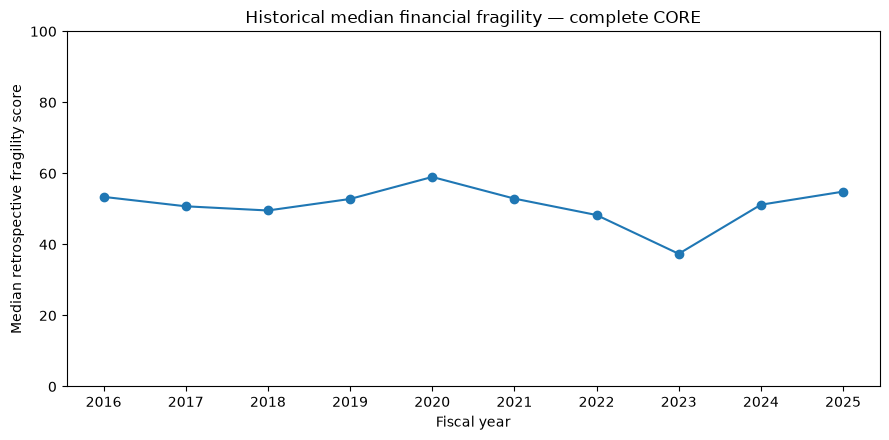

In [9]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(summary_by_year.index, summary_by_year.median_fragility, marker='o')
ax.set(title='Historical median financial fragility — complete CORE',
       xlabel='Fiscal year', ylabel='Median retrospective fragility score')
ax.set_xticks(summary_by_year.index)
ax.set_ylim(0, 100)
fig.tight_layout()
plt.show()

In [10]:
saved_scores = pd.read_csv(PROJECT_ROOT / 'data/processed/financial_fragility_scores.csv')
saved_reference = pd.read_csv(PROJECT_ROOT / 'data/processed/fragility_reference.csv')
assert len(saved_scores) == len(scores) == len(saved_reference)
assert saved_scores.club.nunique() == core.club.nunique()
assert set(zip(saved_scores.club, saved_scores.fiscal_year)) == set(zip(core.club, core.fiscal_year))
assert (saved_scores.fiscal_year.min(), saved_scores.fiscal_year.max()) == (
    core.fiscal_year.min(), core.fiscal_year.max())
for col in ['current_liquidity', 'liability_ratio', 'return_on_assets',
            'financial_fragility_score', 'previous_loss_rate']:
    np.testing.assert_allclose(saved_scores[col], scores[col], rtol=1e-9, atol=1e-9,
                               equal_nan=True)
print('Notebook / generated CSV validation passed.')

Notebook / generated CSV validation passed.


### Methodological decision

The full historical reference replaces the earlier partial reference. Scores are
retrospective percentile comparisons of the entire documented financial CORE,
not fixed ex-ante risk probabilities. Negative equity and previous loss rate
remain auxiliary, outside the composite score. The separate predictive
experiments do not use the fragility score and therefore do not require
retraining after this descriptive rebaseline.